# Week 1 — Run it, then discover a real truth yourself

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/flyrank-bih/flyrank-ml-internship-starter/blob/main/notebooks/01_first_look_and_discovery.ipynb?flush_cache=true)

By the end of this notebook you will have:
1. **Run a real ML pipeline** on real (anonymized) search data and watched a learned model beat a hand-written rule.
2. **Rediscovered a real finding yourself** in ~10 lines of pandas.

No prior ML needed. Everything runs on the small anonymized dataset that ships with this repo — no credentials, no private data.

## 0. Setup (Colab or local)
On Colab this clones the repo and installs requirements. Locally it just moves to the repo root.

In [1]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/flyrank-bih/flyrank-ml-internship-starter"
REPO_DIR = "flyrank-ml-internship-starter"

if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    # find the repo root from wherever this kernel started
    while not os.path.isdir("data/raw") and os.getcwd() != "/":
        os.chdir("..")

print("Working dir:", os.getcwd())
assert os.path.exists("data/raw/content_refresh_anonymized.csv"), "starter CSV not found — are you at the repo root?"
print("Starter data found. You're ready.")

Working dir: /Users/student/Desktop/flyrank-ml-content-refresh
Starter data found. You're ready.


## 1. Run the whole pipeline

This runs `scripts/run_all.py`: prepare features → baseline rule → train 3 models → evaluate → PDF.
It takes ~1 minute on the 30,000-row sample.

In [2]:
# Watch it work — each of the 5 steps prints live as it runs (~1 minute total).
!{sys.executable} scripts/run_all.py



▶ Step 1/5 — Prepare features — clean the data, build the feature vector, define the label


Prepared 30,000 rows from 30,000 raw rows
Wrote /Users/student/Desktop/flyrank-ml-content-refresh/data/processed/refresh_feature_vector.csv



▶ Step 2/5 — Baseline — a transparent hand-written rule to beat


Wrote baseline queue: /Users/student/Desktop/flyrank-ml-content-refresh/data/processed/baseline_refresh_queue.csv
Top-50 declining rate (full data, not the evaluated holdout Precision@50): 0.340



▶ Step 3/5 — Train — logistic regression, decision tree, random forest (client-holdout split)


Trained 3 models on 30,000 rows
Split strategy: client_holdout
Best model: random_forest
Wrote predictions: /Users/student/Desktop/flyrank-ml-content-refresh/data/processed/model_predictions.csv
Wrote model results: /Users/student/Desktop/flyrank-ml-content-refresh/outputs/model_results.json



▶ Step 4/5 — Evaluate — ranked refresh queue, charts, and the Markdown report


Wrote final refresh queue: /Users/student/Desktop/flyrank-ml-content-refresh/outputs/refresh_queue.csv
Wrote model report: /Users/student/Desktop/flyrank-ml-content-refresh/outputs/model_report.md
Wrote charts in: /Users/student/Desktop/flyrank-ml-content-refresh/outputs/charts



▶ Step 5/5 — Report — a shareable PDF summary


Wrote PDF report: /Users/student/Desktop/flyrank-ml-content-refresh/outputs/flyrank_refresh_model_results.pdf

Pipeline complete
Rows scored: 30,000
Best model: random_forest
Queue: outputs/refresh_queue.csv
Report: outputs/model_report.md
PDF: /Users/student/Desktop/flyrank-ml-content-refresh/outputs/flyrank_refresh_model_results.pdf


### What just happened?
The pipeline ranked every page for "refresh review" two ways: a **hand-written rule baseline** and a **learned model**. Let's compare them on **Precision@50** — of the top 50 pages each says to fix first, how many are actually declining?

In [3]:
import json
res = json.load(open("outputs/model_results.json"))

base = res["baseline"]["baseline_precision_at_50"]
rf   = res["models"]["random_forest"]["precision_at_50"]

print(f"Hand-written rule  Precision@50: {base:.3f}   (~{round(base*50)} of the top 50 right)")
print(f"Random forest      Precision@50: {rf:.3f}   (~{round(rf*50)} of the top 50 right)")
print(f"\nThe learned model roughly {rf/base:.1f}x the rule on this metric.")
print("Validation split used:", res["split_strategy"], "(pages from a client are never in both train and test)")

Hand-written rule  Precision@50: 0.240   (~12 of the top 50 right)
Random forest      Precision@50: 0.680   (~34 of the top 50 right)

The learned model roughly 2.8x the rule on this metric.
Validation split used: client_holdout (pages from a client are never in both train and test)


You just ran a real ML system on real search data and saw a learned ranking beat a fixed rule. Now open `outputs/model_report.md` and skim it — that Markdown report is the *shape* of what your own capstone should produce.

## 2. Discover a real truth yourself

The safest, most satisfying early wins are **things you find in the data** — un-leakable, and they *are* the core lesson. Run the three cells below. Each is ~10 lines of pandas and each overturns a common SEO belief.

Every number is **computed live from the shipped CSV** — nothing is hardcoded.

In [4]:
import pandas as pd, numpy as np
df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
print(df.shape[0], "rows,", df.shape[1], "columns")
df.head(3)

30000 rows, 44 columns


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9


### Discovery A — "High search volume means more traffic." Does it?

In [5]:
corr = df["search_volume"].corr(df["impressions_90d"])
print(f"Correlation between search_volume and impressions_90d: {corr:.3f}")
print("Near zero -> keyword search volume barely predicts the traffic a page actually gets.")

Correlation between search_volume and impressions_90d: 0.001
Near zero -> keyword search volume barely predicts the traffic a page actually gets.


### Discovery B — the CTR cliff by position
Click-through rate is not flat: it collapses as you move down the results.

position_tier
page_1      0.3548
top_3       0.3341
striking    0.2558
page_3_5    0.1424
deep        0.0554


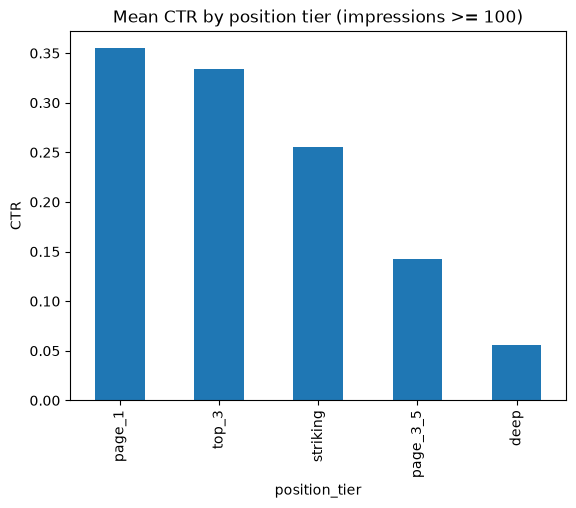

In [6]:
visible = df[df["impressions_90d"] >= 100]
ctr_by_pos = visible.groupby("position_tier")["ctr"].mean().sort_values(ascending=False)
print(ctr_by_pos.round(4).to_string())
ctr_by_pos.plot(kind="bar", title="Mean CTR by position tier (impressions >= 100)", ylabel="CTR");

### Discovery C — is longer content the lever?
Compare word count for **declining** vs **growing** pages.

In [7]:
wc = df.groupby("trend_direction")["word_count"].median()
print(wc.round(0).to_string())
print("\n'down' vs 'up' pages have almost the same median word count -> length is not the lever.")

trend_direction
down      2909.0
flat      2698.0
new       2239.0
stable    2912.0
up        2848.0

'down' vs 'up' pages have almost the same median word count -> length is not the lever.


## 3. 🔧 Your turn

Pick **one** of these and write a few lines below. This is your Week-1 discovery — you'll reference it in your Week-1 research-question write-up (on the InternHQ board).

- Redo Discovery A but only for pages with `impressions_90d > 0` — does the correlation change?
- In Discovery B, which `content_type` has the worst CTR *at the same position tier*?
- Find another belief to test: does `content_age_days` relate to `trend_direction`? Does `avg_position` relate to `ctr`?

**Rules:** describe what you observe as *observed / directional* — never "I proved Google's algorithm." Keep client data out of anything you publish.

           pages  share_down  share_up
age_band                              
90-119 d    5459       0.609     0.147
120-179 d   6555       0.640     0.099
180-269 d   4513       0.595     0.122
270-364 d   7113       0.470     0.134
365+ d      6360       0.426     0.226

All pages: share_down = 0.542, share_up = 0.146


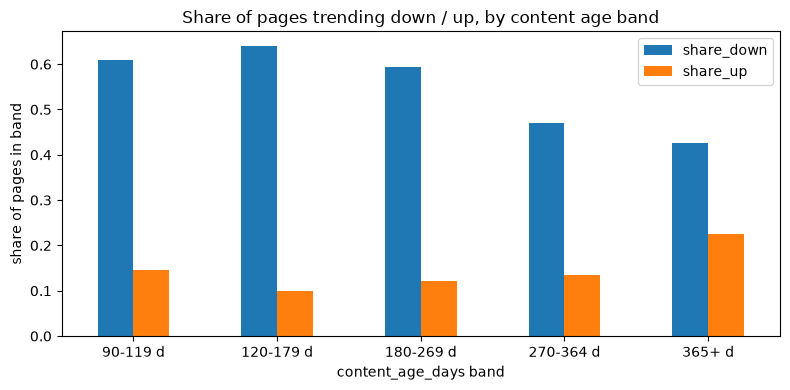

In [8]:
# Your turn: does content_age_days relate to trend_direction?
# Aggregates only: row count and share of "down" / "up" pages per age band.
import matplotlib.pyplot as plt

age_bins   = [90, 120, 180, 270, 365, np.inf]
age_labels = ["90-119 d", "120-179 d", "180-269 d", "270-364 d", "365+ d"]
age_band = pd.cut(df["content_age_days"], bins=age_bins, labels=age_labels, right=False)

trend = df["trend_direction"].str.lower()
age_table = pd.DataFrame({
    "pages":      age_band.value_counts().reindex(age_labels),
    "share_down": trend.eq("down").groupby(age_band, observed=False).mean(),
    "share_up":   trend.eq("up").groupby(age_band, observed=False).mean(),
})
age_table.index.name = "age_band"
assert age_table["pages"].sum() == len(df), "every row should land in exactly one band"

print(age_table.assign(share_down=age_table["share_down"].round(3),
                       share_up=age_table["share_up"].round(3)).to_string())
print(f"\nAll pages: share_down = {trend.eq('down').mean():.3f}, share_up = {trend.eq('up').mean():.3f}")

ax = age_table[["share_down", "share_up"]].plot(kind="bar", rot=0, figsize=(8, 4),
        title="Share of pages trending down / up, by content age band")
ax.set_xlabel("content_age_days band")
ax.set_ylabel("share of pages in band")
plt.tight_layout();


### My Week-1 discovery: content age vs trend direction

**Question.** Does `content_age_days` relate to `trend_direction`? The common belief is "old content decays", so I expected older pages to be trending down more often.

**What I did.** I split `content_age_days` into 5 age bands (90–119, 120–179, 180–269, 270–364 and 365+ days; every page in this slice is at least 90 days old). For each band I counted the pages and worked out what share of them have `trend_direction == "down"` and what share have `"up"`. Then I plotted both shares.

**Observed.**
- Across all 30,000 pages, 54.2% are trending down and 14.6% are trending up.
- Younger pages were down *more* often: 60.9% (90–119 d, 5,459 pages), 64.0% (120–179 d, 6,555 pages), 59.5% (180–269 d, 4,513 pages).
- Older pages were down *less* often: 47.0% (270–364 d, 7,113 pages) and 42.6% (365+ d, 6,360 pages).
- The 365+ band has the highest share trending up: 22.6%, against 14.6% overall.
- So in this slice the pattern runs the opposite way to "old content decays". The drop happens at around 9–10 months. That matches the depth-2 tree in notebook 02, which split on `content_age_days <= 312.5`.

**Caveat.** This is an observational, directional pattern in one anonymized slice (32 clients, one last-30 vs previous-30 day window). It is not causal: age does not *make* a page decline. Age is tangled up with which client a page belongs to (each client has its own content mix and publishing history). Young pages may also just be settling down after an early launch bump. I'm reading this as decision-support context, not a rule.

**Next question.** Does the age pattern still hold *inside* each client (and among pages that actually get impressions), or does it come from a few clients with mostly young content?


In [9]:
# Your discovery here


### Save your work
**Colab:** *File → Save a copy in GitHub* (writes to your own repo — that's your submission) and *File → Save a copy in Drive* (so the session doesn't evaporate).

Next: `02_your_first_readable_model.ipynb` — where the model becomes a rule you can read.